# Predicting experimental treatment effects
## Peng et al. (2026) archive


### How Peng et al. made the predictions

- Each digital twin was prompted with a real person's earlier answers to more than 500 questions from the Twin-2K-500 dataset. The authors supply those answers as text in the prompt.
- The prompt also asked the model to answer a new survey as that person, remaining consistent with their earlier answers and allowing for human uncertainty and biases.
- This demonstration uses the default **GPT-4.1, full-persona, no-reasoning specification at temperature 0.7**. Human and twin responses are linked by participant ID. 

Source: Peng et al., Materials and Methods; Supplementary Materials S2 (prompt template) and S3 (persona construction). [Paper and supplement](https://pmc.ncbi.nlm.nih.gov/articles/PMC13537255/).


### The example in this notebook

Does recalling an experience of gratitude change how people feel? Do their digital twins predict the same changes?

We use the gratitude experiment from Peng et al., *Digital twins are funhouse mirrors*. The description and outcome scoring follow the authors’ Supplementary Materials, section S10.2. [Paper and supplement](https://pmc.ncbi.nlm.nih.gov/articles/PMC13537255/).

Start by comparing the human and twin treatment effects. Then imagine we have collected human responses for only half the sample, and use prediction-powered inference to combine those responses with predictions.

All predictions are already included. No model account or coding agent is required. Run the cells in order with Shift+Enter. Keep the notebook inside the downloaded repository so it can find the included data.

## Before you run the analysis

Complete the setup in the repository README first. Run the following cell only if you need to install the analysis packages in this notebook’s Python environment. The first installation needs an internet connection. Then run the analysis cells in order.

In [ ]:
%pip install -q numpy pandas matplotlib openpyxl https://github.com/Michael-Howes/ppi_py/archive/2dc0ceede320ddf81b4d1050df04fbd1f48bd31b.zip

## 1. The gratitude experiment

Participants spend two minutes responding to a writing prompt.

- **Gratitude prime**. Recall a specific experience when they felt grateful for someone’s kindness or help.
- **Baseline prompt**. Recall their morning routine, such as brushing their teeth or getting dressed.

People and their twins receive the same experimental condition. We use the 508 participants assigned to the gratitude domain of the authors’ larger affective-primes experiment.

After writing, participants complete a manipulation check and further outcome measures.

| Outcome | What it measures | Scale |
|---|---|---|
| Gratitude manipulation check | Average ratings of feeling grateful, thankful and appreciative | 1–7 |
| Downstream composite | Average ratings of uplifting feelings and empathic concern | 1–7 |

We ask whether the model reproduces the effect on gratitude itself and on the downstream composite. 

## Load the workshop data

`gratitude_outcomes.csv` is a prepared workshop file with two rows per participant, one for each outcome. `pd.read_csv` takes the CSV filename. Use the outcome choice below to select the measure you want to analyze.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ppi_py import classical_ols_ci, ppi_ols_ci
import sys

%matplotlib inline

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = str(ROOT / "data/workshop/peng") + "/"
sys.path.insert(0, str(ROOT / "scripts"))
from workshop_helpers import ppi_correlation, effective_sample_size
SEED = 20261013

data = pd.read_csv(DATA + "gratitude_outcomes.csv")
print(data.groupby("outcome").size())
data.head()

No event loop hook running.
outcome
Downstream composite            508
Gratitude manipulation check    508
dtype: int64


,TWIN_ID,Y,Yhat,treated,variable_name,outcome,study
0,9,3.583333,4.416667,0,gratitude,Downstream composite,affective_priming
1,9,3.000000,5.000000,0,gratitude_manipulation_check,Gratitude manipulation check,affective_priming
2,14,6.583333,5.916667,1,gratitude,Downstream composite,affective_priming
3,14,7.000000,6.000000,1,gratitude_manipulation_check,Gratitude manipulation check,affective_priming
4,18,6.416667,6.000000,0,gratitude,Downstream composite,affective_priming


## 2. How people and twins are matched

`TWIN_ID` links each person to their digital twin. `Y` is the person’s response and `Yhat` is the corresponding twin response.

In [2]:
outcome = "Downstream composite"  # Or "Gratitude manipulation check"
selected = data[data["outcome"] == outcome].sort_values("TWIN_ID")
Y = selected["Y"].to_numpy()
Yhat = selected["Yhat"].to_numpy()
treated = selected["treated"].to_numpy()
X = np.column_stack([np.ones(len(Y)), treated])  # Intercept, then treatment.
print(selected.groupby("treated")[["Y", "Yhat"]].mean().round(3))

             Y   Yhat
treated              
0        4.825  4.395
1        5.213  4.897


## 3. Compare treatment effects across outcomes

Let's compare treatments effects estimated on the human responses and the predictions. Every effect is the gratitude-prime mean minus the baseline mean. A positive effect means the prime increases the outcome. The human intervals are approximate 95% intervals. The twin points show the corresponding predicted effects.

In [3]:
rows = []
for name, d in data.groupby("outcome"):
    design = np.column_stack([np.ones(len(d)), d["treated"]])
    lower, upper = classical_ols_ci(design, d["Y"].to_numpy(), alpha=.05)
    means = d.groupby("treated")["Yhat"].mean()
    rows.append([name, (lower[1] + upper[1]) / 2, lower[1], upper[1], means[1] - means[0]])
summary = pd.DataFrame(rows, columns=["outcome", "human", "lower", "upper", "model"])
print(summary.round(3).to_string(index=False))

                     outcome  human  lower  upper  model
        Downstream composite  0.388  0.181  0.595  0.502
Gratitude manipulation check  0.815  0.564  1.066  1.332


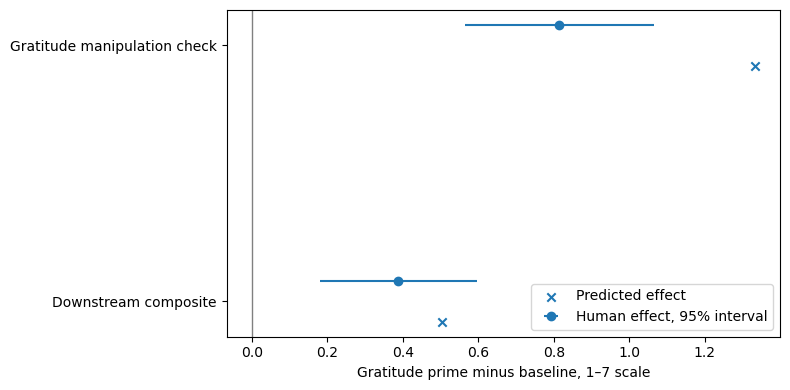

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(summary))
ax.errorbar(summary.human, y + .08, xerr=(summary.upper - summary.lower) / 2,
            fmt="o", label="Human effect, 95% interval")
ax.scatter(summary.model, y - .08, marker="x", label="Predicted effect")
ax.set_yticks(y, summary.outcome)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Gratitude prime minus baseline, 1–7 scale")
ax.legend()
plt.tight_layout()
plt.show()

**Reading this plot**

- The gratitude prime raises the human manipulation-check score by about 0.82 points. Twins predict a larger increase, about 1.33 points.
- The downstream composite rises by about 0.39 points in humans and 0.50 points in twins.
- Twins capture the direction of both effects, but overstate their sizes, especially for the manipulation check.
- These are effects on reported feelings and concern, not observed helping behavior. A plausible treatment effect also does not guarantee accurate predictions for individual people.

## 4. Mixed subjects design with PPI++

Now pretend we have collected human responses for only half the people in each condition. The remaining people have predictions only. We select the half with a fixed random seed and do not use the remaining human answers for estimation or a separate validation exercise.

Compare three estimates: model responses alone, the collected human responses alone, and the human responses combined with predictions through PPI. The package handles estimation and power tuning. With an intercept and binary treatment, coefficient 1 is the treatment effect.

The model-only interval describes model responses across sampled people. It does not establish validity for the human effect. PPI uses the collected human responses to correct prediction bias.

In [5]:
rng = np.random.default_rng(SEED)
labeled = np.zeros(len(Y), dtype=bool)
for arm in [0, 1]:
    indices = np.flatnonzero(treated == arm)
    chosen = rng.choice(indices, size=len(indices) // 2, replace=False)
    labeled[chosen] = True
print("Human responses collected in this illustration:", labeled.sum())
print("People with predictions only:", (~labeled).sum())

Human responses collected in this illustration: 253
People with predictions only: 255


In [6]:
X_human, Y_human, Yhat_human = X[labeled], Y[labeled], Yhat[labeled]
X_silicon, Yhat_silicon = X[~labeled], Yhat[~labeled]
n, N = labeled.sum(), (~labeled).sum()

silicon = classical_ols_ci(X_silicon, Yhat_silicon, alpha=.05)
humans = classical_ols_ci(X_human, Y_human, alpha=.05)
mixed = ppi_ols_ci(X_human, Y_human, Yhat_human, X_silicon, Yhat_silicon,
                   alpha=.05, coord=1)

table = pd.DataFrame([[ci[0][1], ci[1][1]] for ci in [silicon, humans, mixed]],
                     index=["Silicon subjects", "Human subjects", "Mixed subjects"],
                     columns=["lower", "upper"])
table["estimate"] = (table.lower + table.upper) / 2  # These intervals are symmetric.
table["width"] = table.upper - table.lower
print(table.round(3))

                  lower  upper  estimate  width
Silicon subjects  0.302  0.827     0.565  0.525
Human subjects    0.086  0.649     0.367  0.563
Mixed subjects    0.135  0.661     0.398  0.526


Mixed / human interval width: 0.935


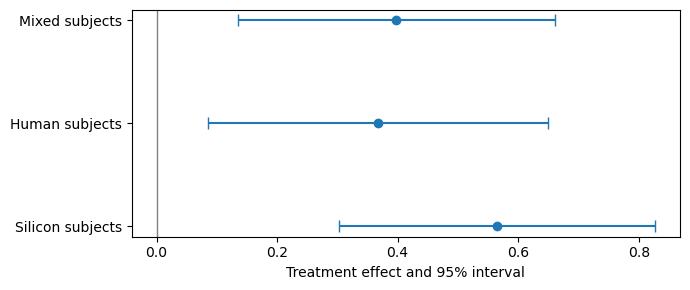

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.errorbar(table.estimate, np.arange(3), xerr=table.width / 2, fmt="o", capsize=4)
ax.set_yticks(np.arange(3), table.index)
ax.axvline(0, color="grey", linewidth=1)
ax.set_xlabel("Treatment effect and 95% interval")
plt.tight_layout()
plt.show()
print("Mixed / human interval width:", round(table.loc["Mixed subjects", "width"] / table.loc["Human subjects", "width"], 3))

## 5. PPI correlation and effective sample size

The **PPI correlation** describes how informative predictions are for estimating the treatment coefficient. It is different from ordinary agreement between human and twin responses.

Think of **effective sample size** as the number of human observations giving the same precision as a combined sample of observations and predictions.

We use the package’s PPI correlation and our fixed numbers of labeled and unlabeled people. No costs or budget are needed. The effective sample size is a large-sample approximation with optimal weighting, not the realized gain from this particular split. Compare it with the interval widths above.

In [8]:
rho = ppi_correlation(X_human, Y_human, Yhat_human)
ess = effective_sample_size(rho, n, N)
print("PPI correlation:", round(rho, 3))
print("Human responses:", n, "| Unlabeled people:", N)
print("Approximate effective sample size:", round(ess, 1))
print("Gain over the human sample (%):", round(100 * (ess / n - 1), 1))

PPI correlation: 0.491
Human responses: 253 | Unlabeled people: 255
Approximate effective sample size: 287.9
Gain over the human sample (%): 13.8


## 6. Where else are predictions useful?

Compare the two gratitude outcomes with the prepared green-energy experiment. In that experiment, people choose an energy supplier. The treatment makes green energy the default with an option to opt out; the comparison requires opting in. The outcome is choosing green energy, coded 0 or 1 for both people and twins.

The next cell uses all complete responses as pilot data for each comparison, then computes the approximate gain for a half-human design. These are three prepared outcome comparisons from two experiments, not a summary of all 19 studies in Peng’s archive.

In [9]:
experiments = pd.read_csv(DATA + "experimental_outcomes.csv")
rows = []
for (study, name), d in experiments.groupby(["study", "outcome"]):
    design = np.column_stack([np.ones(len(d)), d.treated])
    rho = ppi_correlation(design, d.Y.to_numpy(), d.Yhat.to_numpy())
    n = len(d) // 2
    N = len(d) - n
    ess = effective_sample_size(rho, n, N)
    rows.append([study, name, rho, n, N, ess, 100 * (ess / n - 1)])
comparison = pd.DataFrame(rows, columns=["study", "outcome", "ppi_corr", "n", "N", "effective_n", "gain_percent"])
print(comparison.round(3).to_string(index=False))

            study                      outcome  ppi_corr   n   N  effective_n  gain_percent
affective_priming         Downstream composite     0.519 254 254      293.481        15.544
affective_priming Gratitude manipulation check     0.323 254 254      268.011         5.516
     default_eric          Green-energy choice     0.369 300 300      321.867         7.289


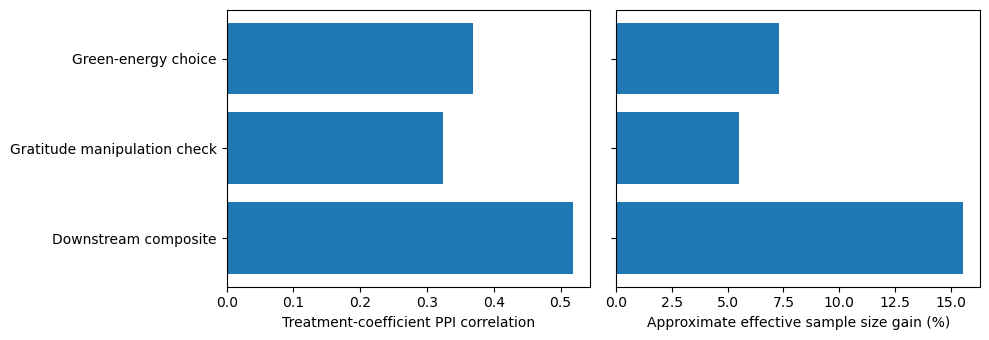

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
y = np.arange(len(comparison))
axes[0].barh(y, comparison.ppi_corr)
axes[0].set_yticks(y, comparison.outcome)
axes[0].set_xlabel("Treatment-coefficient PPI correlation")
axes[1].barh(y, comparison.gain_percent)
axes[1].set_yticks(y, [])
axes[1].set_xlabel("Approximate effective sample size gain (%)")
plt.tight_layout()
plt.show()

**Try another outcome or experiment**

- Change `outcome` in section 2 to `Gratitude manipulation check` and rerun the cells below it. Does the larger predicted treatment effect translate into a larger PPI gain?
- Try green energy using the selection below. Its binary outcome has different units, so compare PPI correlations rather than raw effect sizes across the two experiments.
- The included `default_outcomes.zip` contains analysis tables for all 19 studies. Designs differ, and the compact tables do not include every treatment assignment. Use the [data guide](../data/workshop/peng/README.md) to choose further comparisons carefully.

In [11]:
study_id = "default_eric"
outcome_name = "Green-energy choice"
d = experiments[(experiments.study == study_id) & (experiments.outcome == outcome_name)]
design = np.column_stack([np.ones(len(d)), d.treated])
rho = ppi_correlation(design, d.Y.to_numpy(), d.Yhat.to_numpy())
n = len(d) // 2
N = len(d) - n  # Try N = 5 * n.
print("PPI correlation:", round(rho, 3))
print("Approximate effective sample size:", round(effective_sample_size(rho, n, N), 1))

PPI correlation: 0.369
Approximate effective sample size: 321.9


## Share one result

- Explain the treatment, baseline and outcome in plain language.
- Show one plot and say what it tells you about the twins’ predictions.
- Does your conclusion change between the manipulation check and downstream composite?
- Give one limitation and one question you would investigate next.

A few bullet points are enough. Data preparation and original source links are in the [Peng data guide](../data/workshop/peng/README.md).